In [201]:
import numpy as np
from scipy.io import loadmat
from scipy.signal import savgol_filter  


def dataset_to_iddata(dataset, K, F):

    runs = dataset.runs
    # When using squeeze_me=True, single dimension structs become 1D arrays
    if not isinstance(runs, np.ndarray):
        runs = np.array([runs])

    R = runs.size

    # --- first pass: total number of samples ---
    Ni = np.zeros(R, dtype=int)
    for i in range(R):
        Ni[i] = runs[i].x_true.shape[0]  # length of this run
    Ntot = Ni.sum()

    # Preallocate
    data = {}
    data["t"]        = np.zeros(Ntot)
    data["q_meas"]   = np.zeros((2, Ntot))
    data["qd_filt"]  = np.zeros((2, Ntot))
    data["qdd_filt"] = np.zeros((2, Ntot))
    data["q"]        = np.zeros((2, Ntot))
    data["qd"]       = np.zeros((2, Ntot))
    data["qdd"]      = np.zeros((2, Ntot))
    data["tau_meas"] = np.zeros((2, Ntot))
    data["KE"]       = np.zeros(Ntot)
    data["momentum"] = np.zeros((2,Ntot))

    # assume constant dt across runs
    dt = runs[0].time[1] - runs[0].time[0]
    data["dt"] = float(dt)

    idx0 = 0  # starting index in the global arrays for each run
    for i in range(R):
        r = runs[i]
        ti = np.asarray(r.time).ravel()
        Ni_i = Ni[i]

        start = idx0
        end = idx0 + Ni_i  # Python slice is [start, end)

        ke_run = np.asarray(r.KE).ravel()
        ke_run = ke_run.reshape(-1)[:Ni_i]

        # Fill raw (unfiltered) data
        for k in range(Ni_i):
            j = start + k  # global index
            xk = np.asarray(r.x_true[k, :]).ravel()   # [th1 th2 dth1 dth2]
            yk = np.asarray(r.y_meas[k, :]).ravel()   # [th1 th2 dth1 dth2]
            pk = np.asarray(r.p[k, :]).ravel()   # [p1 p2]

            data["t"][j]            = ti[k]
            data["q_meas"][:, j]    = yk[0:2]         # measured positions
            data["q"][:, j]         = xk[0:2]         # true positions
            data["qd"][:, j]        = xk[2:4]         # true velocities
            data["qdd"][:, j]       = np.asarray(r.ddq[k, :]).ravel()
            data["tau_meas"][:, j]  = np.asarray(r.u_applied[k, :]).ravel()
            data["KE"][j] = ke_run[k]
            data["momentum"][:,j] = pk[0:2]

        # ---- Filtering for this run ----
        # Position filtering with Savitzky–Golay (sgolayfilt)
        q_meas_run = data["q_meas"][:, start:end]  # shape (2, Ni_i)

        q_filt1 = savgol_filter(q_meas_run[0, :], window_length=F, polyorder=K, mode="interp")
        q_filt2 = savgol_filter(q_meas_run[1, :], window_length=F, polyorder=K, mode="interp")
        data["q_filt"] = data.get("q_filt", np.zeros((2, Ntot)))
        data["q_filt"][0, start:end] = q_filt1
        data["q_filt"][1, start:end] = q_filt2

        # Velocities from central differences of filtered positions
        q_filt_run = data["q_filt"][:, start:end]  # (2, Ni_i)

        # interior points
        for j in range(start + 1, end - 1):
            idx_prev = j - 1
            idx_next = j + 1
            data["qd_filt"][:, j] = (data["q_filt"][:, idx_next] -
                                     data["q_filt"][:, idx_prev]) / (2.0 * data["dt"])

        # boundaries (one-sided)
        data["qd_filt"][:, start] = (data["q_filt"][:, start + 1] -
                                     data["q_filt"][:, start]) / data["dt"]
        data["qd_filt"][:, end - 1] = (data["q_filt"][:, end - 1] -
                                       data["q_filt"][:, end - 2]) / data["dt"]

        # Filter velocities
        qd_run = data["qd_filt"][:, start:end]
        qd_filt1 = savgol_filter(qd_run[0, :], window_length=F, polyorder=K, mode="interp")
        qd_filt2 = savgol_filter(qd_run[1, :], window_length=F, polyorder=K, mode="interp")
        data["qd_filt"][0, start:end] = qd_filt1
        data["qd_filt"][1, start:end] = qd_filt2

        # Accelerations from filtered velocities
        qd_filt_run = data["qd_filt"][:, start:end]

        for j in range(start + 1, end - 1):
            idx_prev = j - 1
            idx_next = j + 1
            data["qdd_filt"][:, j] = (data["qd_filt"][:, idx_next] -
                                      data["qd_filt"][:, idx_prev]) / (2.0 * data["dt"])

        data["qdd_filt"][:, start] = (data["qd_filt"][:, start + 1] -
                                      data["qd_filt"][:, start]) / data["dt"]
        data["qdd_filt"][:, end - 1] = (data["qd_filt"][:, end - 1] -
                                        data["qd_filt"][:, end - 2]) / data["dt"]

        # Optional: smooth accelerations too (as in MATLAB)
        qdd_run = data["qdd_filt"][:, start:end]
        qdd_filt1 = savgol_filter(qdd_run[0, :], window_length=F, polyorder=K, mode="interp")
        qdd_filt2 = savgol_filter(qdd_run[1, :], window_length=F, polyorder=K, mode="interp")
        data["qdd_filt"][0, start:end] = qdd_filt1
        data["qdd_filt"][1, start:end] = qdd_filt2

        # move starting index for next run
        idx0 = end

    return data


if __name__ == "__main__":
    # Load the same .mat file as in MATLAB
    S = loadmat("planar_2dof_dataset_no_noise_linear_friction.mat",
                squeeze_me=True, struct_as_record=False)
    dataset = S["dataset"]

    F = 251
    K = 2
    data = dataset_to_iddata(dataset, K, F)


In [202]:
# Define system parameters
m1 = 1.6537
l1 = 0.343
r1 = 0.29
I1 = 0.039


m2 = 0.9982
l2 = 0.267
r2 = 0.175
I2 = 0.0081

a1 = m1*r1**2 + m2*l1**2 + I1
a2 = m2*r2**2 + I2
b = m2*l1*r2

# Function to compute total energy
def compute_total_energy(state):
    theta1, theta2, dtheta1, dtheta2 = state

    # Mass matrix
    M = np.array([[a1 + a2 + 2*b*np.cos(theta2),  a2 + np.cos(theta2)],
                  [a2 + b*np.cos(theta2), a2]])
    
    # Kinetic energy
    dtheta = np.array([dtheta1, dtheta2])
    T = 0.5 * dtheta @ M @ dtheta.T
    
    # Potential energy
    V = 0
    
    return T + V

# Function to compute momentum p = M * dtheta
def compute_momentum(state):
    theta1, theta2, dtheta1, dtheta2 = state
    
    # Mass matrix
    M = np.array([[a1 + a2 + 2*b*np.cos(theta2),  a2 + b*np.cos(theta2)],
                  [a2 + b*np.cos(theta2), a2]])
    
    # Compute momentum
    dtheta = np.array([dtheta1, dtheta2])
    p = M @ dtheta  # Generalized momentum
    
    return p




In [203]:
runs = dataset.runs
# if not isinstance(runs, np.ndarray):
#     runs = np.array([runs])

trajectories = {"time": data["t"], "states": []}

for i, r in enumerate(runs):
    Ni = r.x_true.shape[0]
    print(f"Processing run {i+1} with {Ni} samples...")

    #THIS IS STILL NOISE FREE X
    theta1 = np.array([r.x_true[j, 0] for j in range(Ni)])
    theta2 = np.array([r.x_true[j, 1] for j in range(Ni)])
    dtheta1 = np.array([r.x_true[j, 2] for j in range(Ni)])
    dtheta2 = np.array([r.x_true[j, 3] for j in range(Ni)])

    tau1 = np.array([r.u_applied[j, 0] for j in range(Ni)])
    tau2 = np.array([r.u_applied[j, 1] for j in range(Ni)])

    # energy = np.array([compute_total_energy(r.x_true[j, :]) for j in range(Ni)])
    # momentum = np.array([compute_momentum(r.x_true[j, :]) for j in range(Ni)])

    energy = np.array([r.KE[j] for j in range(Ni)])
    momentum = np.array([r.p[j, :] for j in range(Ni)])

    trajectories["states"].append({
        "initial_condition": r.x_true[0, :],
        "theta1": theta1,
        "theta2": theta2,
        "dtheta1": dtheta1,
        "dtheta2": dtheta2,
        "tau1": tau1,
        "tau2": tau2,
        "p1": momentum[:, 0],
        "p2": momentum[:, 1],
        "total_energy": energy
    })

trajectories["states"]

Processing run 1 with 5001 samples...
Processing run 2 with 5001 samples...
Processing run 3 with 5001 samples...
Processing run 4 with 5001 samples...
Processing run 5 with 5001 samples...
Processing run 6 with 5001 samples...
Processing run 7 with 5001 samples...
Processing run 8 with 5001 samples...
Processing run 9 with 5001 samples...
Processing run 10 with 5001 samples...
Processing run 11 with 5001 samples...
Processing run 12 with 5001 samples...
Processing run 13 with 5001 samples...
Processing run 14 with 5001 samples...
Processing run 15 with 5001 samples...
Processing run 16 with 5001 samples...
Processing run 17 with 5001 samples...
Processing run 18 with 5001 samples...
Processing run 19 with 5001 samples...
Processing run 20 with 5001 samples...


[{'initial_condition': array([ 2.25496777,  2.58181318, -0.09597229, -0.33342856]),
  'theta1': array([2.25496777, 2.25487175, 2.25477561, ..., 2.10095857, 2.10088679,
         2.10081499]),
  'theta2': array([2.58181318, 2.58147989, 2.58114687, ..., 2.37051458, 2.37052549,
         2.37053656]),
  'dtheta1': array([-0.09597229, -0.0960788 , -0.09618514, ..., -0.071772  ,
         -0.07178598, -0.07179986]),
  'dtheta2': array([-0.33342856, -0.333156  , -0.33288309, ...,  0.01082791,
          0.01098883,  0.01114965]),
  'tau1': array([-0.0355875 , -0.03555229, -0.03551701, ..., -0.00555293,
         -0.00552461, -0.0054963 ]),
  'tau2': array([0.00378066, 0.00379847, 0.00381628, ..., 0.00677126, 0.00677062,
         0.00676996]),
  'p1': array([-0.01829175, -0.0183254 , -0.01835901, ..., -0.01786347,
         -0.01786758, -0.01787165]),
  'p2': array([-0.01173218, -0.01172137, -0.01171055, ...,  0.00072734,
          0.00073366,  0.00073997]),
  'total_energy': array([0.00283367, 0.0

In [204]:
import numpy as np

t_eval = data["t"]  # Time points
state_trajectories = trajectories["states"]  # List of dictionaries
dt = t_eval[1]-t_eval[0]

# Prepare dataset: single state transitions (x_t -> x_t+1)
X, Y, U = [], [], []

for traj in state_trajectories:
    theta1 = traj["theta1"]
    theta2 = traj["theta2"]
    p1 = traj["p1"]
    p2 = traj["p2"]
    tau1 = traj["tau1"]
    tau2 = traj["tau2"]
    
    for t in range(len(theta1) - 1):  # One-step transitions
        current_state = np.array([theta1[t], theta2[t], p1[t], p2[t]])
        next_state = np.array([theta1[t+1], theta2[t+1], p1[t+1], p2[t+1]])
        current_input = np.array([tau1[t], tau2[t]])
        
        X.append(current_state)
        Y.append(next_state)
        U.append(current_input)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)
U = np.array(U, dtype=np.float32)



In [205]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint_adjoint as odeint
import torch.nn.functional as F

def make_mlp(in_dim, out_dim, hidden=(128,128), activation=nn.Tanh):
    layers = []
    d = in_dim
    for h in hidden:
        layers.append(nn.Linear(d, h))
        layers.append(activation())
        d = h
    layers.append(nn.Linear(d, out_dim))   # last layer no activation
    return nn.Sequential(*layers)

class LowerTriangularNN(nn.Module):
    """
    This neural network outputs (N^2 + N)/2 values corresponding to
    the lower triangular entries of a symmetric matrix.

    The last-layer activation ensures diagonal positivity (Softplus + ε).
    """
    def __init__(self, n_dim, hidden_dims=(64, 64), eps=1e-3):
        super().__init__()

        self.n_dim = n_dim
        self.eps = eps

        # Number of parameters needed for lower triangular matrix
        self.out_dim = (n_dim * (n_dim + 1)) // 2

        # Build feed-forward network
        layers = []
        input_dim = n_dim

        for h in hidden_dims:
            layers.append(nn.Linear(input_dim, h))
            layers.append(nn.Tanh())
            input_dim = h

        # Final layer outputs LT matrix entries
        layers.append(nn.Linear(input_dim, self.out_dim))

        self.net = nn.Sequential(*layers)
        self.softplus = nn.Softplus()

    def forward(self, x):
        """
        Returns a symmetric positive-definite matrix for each sample x.
        """
        batch_size = x.shape[0]

        raw_output = self.net(x)

        # Split indices: diagonal first, then off-diagonals
        L = x.new_zeros(batch_size, self.n_dim, self.n_dim)

        # Fill lower-triangular entries
        idx = 0
        for i in range(self.n_dim):
            # Diagonal entry: force positivity
            L[:, i, i] = self.softplus(raw_output[:, idx]) + self.eps
            idx += 1

            # Off-diagonal entries
            for j in range(i + 1, self.n_dim):
                L[:, j, i] = raw_output[:, idx]
                idx += 1

        # Construct symmetric PD matrix:
        # M = L * L^T 
        M = L @ L.transpose(1, 2)
        return M


class ActuatorNN(nn.Module):
    """Map q -> B(q) (n x m) matrix. Input: q [B,n], Output: [B, n, m]."""
    def __init__(self, q_dim, u_dim, hidden=(128,128)):
        super().__init__()
        out_dim = q_dim * u_dim
        self.net = make_mlp(2*q_dim, out_dim, hidden=hidden)

    def forward(self, q):
        inp = torch.cat([torch.sin(q), torch.cos(q)], dim=-1)
        vec = self.net(inp)  # [B, n*m]
        Bmat = vec.view(vec.shape[0], -1, int(vec.shape[-1] // q.shape[-1]))  # [B, n, m]
        return Bmat

# Define the Hamiltonian Neural Network 
class HamiltonianNN(nn.Module):
    # def __init__(self, input_dim=6, hidden_dim=200, output_dim=1): old
    def __init__(self, q_dim, mass_nn,p_dim=None):
        super().__init__()
        self.q_dim = q_dim
        self.p_dim = q_dim if p_dim is None else p_dim
        self.mass_nn = mass_nn
        # self.diss_nn = diss_nn
        # self.actuator_nn = actuator_nn

    def kinetic_energy(self, q, p):
        # q: [B, q_dim], p: [B, q_dim]

        #NN mass matrix:
        M = self.mass_nn(q)                # [B, q, q]

        #Real mass matrix
        # M = FixedMassMatrix(q)

        Minv = torch.linalg.inv(M)         # [B, q, q]
        # compute 0.5 p^T Minv p
        p_col = p.unsqueeze(-1)            # [B, q, 1]
        tmp = Minv @ p_col                 # [B, q, 1]
        T = 0.5 * (p_col * tmp).sum(dim=1).squeeze(-1)  # [B]
        return T

    def forward(self, q, p):
        T = self.kinetic_energy(q, p)
        return T  # H (no potentialk)

class HamiltonianDynamics(nn.Module):
    """
    Given HamiltonianModel H(q,p), compute (dq/dt, dp/dt) using autograd:
      dq/dt =  ∂H/∂p
      dp/dt = -∂H/∂q + damping + actuators
    """
    def __init__(self, hamiltonian_model, mass_nn=None, diss_nn=None, actuator_nn=None):
        super().__init__()
        self.hamiltonian_model = hamiltonian_model
        self.mass_nn = mass_nn
        self.diss_nn = diss_nn
        self.actuator_nn = actuator_nn
    # Define the learned Hamiltonian dynamics
    def forward(self, t, x, u):
        # x: [B, 2*q_dim] concatenated [q, p]
        # q, p = torch.split(x, x.shape[-1]//2, dim=-1)
        # q.requires_grad_(True)
        # p.requires_grad_(True)
        # x_for_grad = torch.cat([q, p], dim=-1)

        # H = self.hamiltonian_model(q, p)  # [B]

        x = x.clone().detach().requires_grad_(True)  # Ensure x requires gradients
        q, p = torch.split(x, x.shape[-1]//2, dim=-1)
        q.requires_grad_(True)
        p.requires_grad_(True)
        H = self.hamiltonian_model(q,p)  # Compute Hamiltonian

        # compute gradient dH/dx = [dH/dq, dH/dp]
        # Compute gradients ∂H/∂x
        dH = torch.autograd.grad(outputs=H, inputs=x, grad_outputs=torch.ones_like(H), create_graph=True)[0]
            
        dH_dq = dH[:, :q.shape[-1]]
        dH_dp = dH[:, q.shape[-1]:]

        dq_dt = dH_dp
        dp_dt = -dH_dq

        # add damping and actuation
        D = self.diss_nn(q)

        damping = -torch.bmm(D,dq_dt.unsqueeze(-1)).squeeze(-1)
 
        A = self.actuator_nn(q)
        # tau = torch.bmm(A,u.unsqueeze(-1)).squeeze(-1)
        # actuation = tau
        actuation = u
        dp_dt = dp_dt + damping + actuation  # add to generalized forces 
        
        return torch.cat([dq_dt, dp_dt], dim=-1)

class BatchDynamics(nn.Module):
    def __init__(self, dynamics, u_batch):
        super().__init__()
        self.dynamics = dynamics
        self.u_batch = u_batch  # store the control for this batch

    def forward(self, t, x):
        # x: [B, 2*q_dim]
        return self.dynamics(t, x, self.u_batch)

def rk4_step(odefunc, x, t, dt):
    # odefunc: callable(t, x) 
    k1 = odefunc(t, x)
    k2 = odefunc(t + dt/2, x + dt * k1 / 2)
    k3 = odefunc(t + dt/2, x + dt * k2 / 2)
    k4 = odefunc(t + dt,   x + dt * k3)
    x_next = x + dt * (k1 + 2*k2 + 2*k3 + k4) / 6
    return x_next


In [206]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint_adjoint as odeint
import torch.nn.functional as F

def make_mlp(in_dim, out_dim, hidden=(128,128), activation=nn.Tanh):
    layers = []
    d = in_dim
    for h in hidden:
        layers.append(nn.Linear(d, h))
        layers.append(activation())
        d = h
    layers.append(nn.Linear(d, out_dim))   # last layer no activation
    return nn.Sequential(*layers)

class LowerTriangularNN(nn.Module):
    """
    This neural network outputs (N^2 + N)/2 values corresponding to
    the lower triangular entries of a symmetric matrix.

    The last-layer activation ensures diagonal positivity (Softplus + ε).
    """
    def __init__(self, n_dim, hidden_dims=(64, 64), eps=1e-3):
        super().__init__()

        self.n_dim = n_dim
        self.eps = eps

        # Number of parameters needed for lower triangular matrix
        self.out_dim = (n_dim * (n_dim + 1)) // 2

        # Build feed-forward network
        layers = []
        input_dim = n_dim

        for h in hidden_dims:
            layers.append(nn.Linear(input_dim, h))
            layers.append(nn.Tanh())
            input_dim = h

        # Final layer outputs LT matrix entries
        layers.append(nn.Linear(input_dim, self.out_dim))

        self.net = nn.Sequential(*layers)
        self.softplus = nn.Softplus()

    def forward(self, x):
        """
        Returns a symmetric positive-definite matrix for each sample x.
        """
        batch_size = x.shape[0]

        raw_output = self.net(x)

        # Split indices: diagonal first, then off-diagonals
        L = x.new_zeros(batch_size, self.n_dim, self.n_dim)

        # Fill lower-triangular entries
        idx = 0
        for i in range(self.n_dim):
            # Diagonal entry: force positivity
            L[:, i, i] = self.softplus(raw_output[:, idx]) + self.eps
            idx += 1

            # Off-diagonal entries
            for j in range(i + 1, self.n_dim):
                L[:, j, i] = raw_output[:, idx]
                idx += 1

        # Construct symmetric PD matrix:
        # M = L * L^T 
        M = L @ L.transpose(1, 2)
        return M


class ActuatorNN(nn.Module):
    """Map q -> B(q) (n x m) matrix. Input: q [B,n], Output: [B, n, m]."""
    def __init__(self, q_dim, u_dim, hidden=(128,128)):
        super().__init__()
        out_dim = q_dim * u_dim
        self.net = make_mlp(2*q_dim, out_dim, hidden=hidden)

    def forward(self, q):
        inp = torch.cat([torch.sin(q), torch.cos(q)], dim=-1)
        vec = self.net(inp)  # [B, n*m]
        Bmat = vec.view(vec.shape[0], -1, int(vec.shape[-1] // q.shape[-1]))  # [B, n, m]
        return Bmat

# Define the Hamiltonian Neural Network 
class HamiltonianNN(nn.Module):
    # def __init__(self, input_dim=6, hidden_dim=200, output_dim=1): old
    def __init__(self, q_dim, mass_nn,p_dim=None):
        super().__init__()
        self.q_dim = q_dim
        self.p_dim = q_dim if p_dim is None else p_dim
        self.mass_nn = mass_nn
        # self.diss_nn = diss_nn
        # self.actuator_nn = actuator_nn

    def kinetic_energy(self, q, p):
        # q: [B, q_dim], p: [B, q_dim]

        #NN mass matrix:
        M = self.mass_nn(q)                # [B, q, q]

        #Real mass matrix
        # M = FixedMassMatrix(q)

        Minv = torch.linalg.inv(M)         # [B, q, q]
        # compute 0.5 p^T Minv p
        p_col = p.unsqueeze(-1)            # [B, q, 1]
        tmp = Minv @ p_col                 # [B, q, 1]
        T = 0.5 * (p_col * tmp).sum(dim=1).squeeze(-1)  # [B]
        return T

    def forward(self, q, p):
        T = self.kinetic_energy(q, p)
        return T  # H (no potentialk)

class HamiltonianDynamics(nn.Module):
    """
    Given HamiltonianModel H(q,p), compute (dq/dt, dp/dt) using autograd:
      dq/dt =  ∂H/∂p
      dp/dt = -∂H/∂q + damping + actuators
    """
    def __init__(self, hamiltonian_model, mass_nn=None, diss_nn=None, actuator_nn=None):
        super().__init__()
        self.hamiltonian_model = hamiltonian_model
        self.mass_nn = mass_nn
        self.diss_nn = diss_nn
        self.actuator_nn = actuator_nn
    # Define the learned Hamiltonian dynamics
    def forward(self, t, x, u):
        # x: [B, 2*q_dim] concatenated [q, p]
        # q, p = torch.split(x, x.shape[-1]//2, dim=-1)
        # q.requires_grad_(True)
        # p.requires_grad_(True)
        # x_for_grad = torch.cat([q, p], dim=-1)

        # H = self.hamiltonian_model(q, p)  # [B]

        x = x.clone().detach().requires_grad_(True)  # Ensure x requires gradients
        q, p = torch.split(x, x.shape[-1]//2, dim=-1)
        q.requires_grad_(True)
        p.requires_grad_(True)
        H = self.hamiltonian_model(q,p)  # Compute Hamiltonian

        # compute gradient dH/dx = [dH/dq, dH/dp]
        # Compute gradients ∂H/∂x
        dH = torch.autograd.grad(outputs=H, inputs=x, grad_outputs=torch.ones_like(H), create_graph=True)[0]
            
        dH_dq = dH[:, :q.shape[-1]]
        dH_dp = dH[:, q.shape[-1]:]

        dq_dt = dH_dp
        dp_dt = -dH_dq

        # add damping and actuation
        D = self.diss_nn(q)

        damping = -torch.bmm(D,dq_dt.unsqueeze(-1)).squeeze(-1)
 
        A = self.actuator_nn(q)
        # tau = torch.bmm(A,u.unsqueeze(-1)).squeeze(-1)
        # actuation = tau
        actuation = u
        dp_dt = dp_dt + damping + actuation  # add to generalized forces 
        
        return torch.cat([dq_dt, dp_dt], dim=-1)

class BatchDynamics(nn.Module):
    def __init__(self, dynamics, u_batch):
        super().__init__()
        self.dynamics = dynamics
        self.u_batch = u_batch  # store the control for this batch

    def forward(self, t, x):
        # x: [B, 2*q_dim]
        return self.dynamics(t, x, self.u_batch)

def rk4_step(odefunc, x, t, dt):
    # odefunc: callable(t, x) 
    k1 = odefunc(t, x)
    k2 = odefunc(t + dt/2, x + dt * k1 / 2)
    k3 = odefunc(t + dt/2, x + dt * k2 / 2)
    k4 = odefunc(t + dt,   x + dt * k3)
    x_next = x + dt * (k1 + 2*k2 + 2*k3 + k4) / 6
    return x_next


In [207]:

import numpy as np

t_eval = data["t"]  # Time points
state_trajectories = trajectories["states"]  # List of dictionaries
dt = float(t_eval[1] - t_eval[0])

list_of_runs = []   # <-- this will contain each trajectory in full sequential form

for traj in state_trajectories:

    theta1 = np.asarray(traj["theta1"], dtype=np.float32)
    theta2 = np.asarray(traj["theta2"], dtype=np.float32)
    p1     = np.asarray(traj["p1"],     dtype=np.float32)
    p2     = np.asarray(traj["p2"],     dtype=np.float32)
    tau1   = np.asarray(traj["tau1"],   dtype=np.float32)
    tau2   = np.asarray(traj["tau2"],   dtype=np.float32)

    T = len(theta1)

    # stack states: shape [T, 4]
    x_seq = np.stack([theta1, theta2, p1, p2], axis=1)

    # stack controls: shape [T, 2]
    u_seq = np.stack([tau1, tau2], axis=1)

    # optional sanity check
    assert x_seq.shape == (T, 4)
    assert u_seq.shape == (T, 2)

    list_of_runs.append({
        "x": x_seq,   # [T, 4]
        "u": u_seq,   # [T, 2]
    })

print(f"Prepared {len(list_of_runs)} runs.")

Prepared 20 runs.


In [216]:
import math
import matplotlib.pyplot as plt
import torch
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

class SequenceDataset(Dataset):
    """
    Takes list_of_runs where each run is dict-like with keys 'x' (T x D) and 'u' (T x U).
    Samples contiguous sequences of length `seq_len` that *start at t0* for each run.
    """
    def __init__(self, list_of_runs, seq_len):
        self.runs = list_of_runs
        self.seq_len = int(seq_len)
        self._rebuild_start_indices()

    def _rebuild_start_indices(self):
        # Only allow sequences that start at index 0 (t0) for each run
        self.start_indices = []
        for run_i, run in enumerate(self.runs):
            T = run['x'].shape[0]
            if T >= self.seq_len + 1:
                self.start_indices.append((run_i, 0))

    def set_seq_len(self, seq_len):
        self.seq_len = int(seq_len)
        self._rebuild_start_indices()

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        run_i, s = self.start_indices[idx]
        run = self.runs[run_i]
        x_seq = run['x'][s:s+self.seq_len+1]   # length seq_len+1 for x0..x_T
        u_seq = run['u'][s:s+self.seq_len]     # controls for steps 0..T-1
        return torch.from_numpy(x_seq).float(), torch.from_numpy(u_seq).float()

# hyperparams
batch_size = 5
# Curriculum parameters: start with short sequences and grow to max
seq_len_min = 1000   # initial short sequences starting at t0
seq_len_max = 5000   # maximum sequence length to train with
lr = 1e-4
epochs = 80
device = torch.device("cpu") #if torch.backends.mps.is_available() else torch.device("cpu")
q_dim = 2

# instantiate networks 
mass_nn = LowerTriangularNN(q_dim, hidden_dims=(128,128)).to(device)
diss_nn = LowerTriangularNN(q_dim, hidden_dims=(64,64)).to(device)
actuator_nn = ActuatorNN(q_dim, u_dim=2, hidden=(2,2)).to(device)

# # load saved state dict (make sure path is correct)
# state = torch.load("modular_hnn_state.pth", map_location=device)

# # If you saved separate state_dicts under keys, load them:
# if 'mass_nn' in state or 'diss_nn' in state or 'actuator_nn' in state:
#     if 'mass_nn' in state:
#         mass_nn.load_state_dict(state['mass_nn'])
#     if 'diss_nn' in state:
#         diss_nn.load_state_dict(state['diss_nn'])
#     if 'actuator_nn' in state:
#         actuator_nn.load_state_dict(state['actuator_nn'])
# else:
#     # if you saved a single state_dict (older variant), try to load into whole model later
#     print("Warning: expected keys mass_nn/diss_nn/actuator_nn not found in the PTH file.")

ham_model = HamiltonianNN(q_dim, mass_nn)
dynamics = HamiltonianDynamics(ham_model, diss_nn=diss_nn, actuator_nn=actuator_nn).to(device)

optim_ = optim.Adam(dynamics.parameters(), lr=lr,weight_decay=1e-6, betas = [0.9, 0.999])
mse = nn.MSELoss()

# create dataset with initial short sequences starting at t0
dataset = SequenceDataset(list_of_runs, seq_len_min)
# Note: DataLoader is (re)created at each epoch to pick up dataset length changes

dynamics.to(device)

# optional LR scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optim_, factor=0.5, patience=10)

loss_history = []

for epoch in range(epochs):
    # curriculum schedule (linear ramp)
    seq_len = int(seq_len_min + (seq_len_max - seq_len_min) * (epoch / max(1, epochs - 1)))
    seq_len = max(seq_len_min, min(seq_len, seq_len_max))
    dataset.set_seq_len(seq_len)

    # recreate dataloader so it sees the new dataset length and shuffle order
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    dynamics.train()
    epoch_loss = 0.0

    print(f"Epoch {epoch+1}/{epochs}  seq_len={seq_len}  batches={len(dataloader)}  available_runs={len(dataset)}")

    for x_seq_batch, u_seq_batch in dataloader:
        # shapes:
        # x_seq_batch: [B, seq_len+1, state_dim]  (we have x0..x_T)
        # u_seq_batch: [B, seq_len, u_dim]
        x_seq_batch = x_seq_batch.to(device)    # ground-truth
        u_seq_batch = u_seq_batch.to(device)

        # initial state
        x_pred = x_seq_batch[:, 0, :].clone()   # [B, state_dim]
        x_true_next = x_pred
        optim_.zero_grad()

        # define batched ode_fn using u at each step (we will pass per-step u inside loop)
        def ode_fn(t, x, u_step):
            # dynamics should accept (t, x, u) where x: [B,D], u: [B,U]
            return dynamics(t, x, u_step)

        # multi-step rollout
        preds = []
        t_now = 0
        loss = 0.0
        for k in range(seq_len):
            u_step = u_seq_batch[:, k, :]        # [B, u_dim]
            # wrap ode_fn for RK4 call (lambda capturing u_step)
            f = lambda tt, xx, u=u_step: ode_fn(tt, xx, u)
            # if k % 75 == 0:
            #     # Use true measurement every 5th step (e.g., assimilation step)
            #     x_true = x_true_next  # or x_assimilated, x_updated, etc.
            # else:
            #     # Free run / prediction only
            x_true = x_pred
            x_pred = rk4_step(f, x_true, t_now + k*dt, dt)   # [B, D]
            preds.append(x_pred)
            # compare to ground truth at step k+1
            x_true_next = x_seq_batch[:, k+1, :].to(device)
            # take only the first two components
            loss = loss + mse(x_pred[:, :2], x_true_next[:, :2])    
        # average loss across steps
        loss = loss / seq_len
        loss.backward()
        # gradient clipping
        torch.nn.utils.clip_grad_norm_(dynamics.parameters(), 1.0)
        optim_.step()

        epoch_loss += loss.item()

    # avoid division by zero when dataset smaller than batch
    if len(dataloader) > 0:
        epoch_loss /= len(dataloader)
    loss_history.append(epoch_loss)
    # scheduler step with the metric
    scheduler.step(epoch_loss)
    print(f"Epoch {epoch+1}/{epochs} loss={epoch_loss:.6e}")

Epoch 1/80  seq_len=1000  batches=4  available_runs=20
Epoch 1/80 loss=1.999809e-02
Epoch 2/80  seq_len=1050  batches=4  available_runs=20
Epoch 2/80 loss=2.048536e-02
Epoch 3/80  seq_len=1101  batches=4  available_runs=20
Epoch 3/80 loss=2.079033e-02
Epoch 4/80  seq_len=1151  batches=4  available_runs=20
Epoch 4/80 loss=2.092051e-02
Epoch 5/80  seq_len=1202  batches=4  available_runs=20
Epoch 5/80 loss=2.121078e-02
Epoch 6/80  seq_len=1253  batches=4  available_runs=20
Epoch 6/80 loss=2.133554e-02
Epoch 7/80  seq_len=1303  batches=4  available_runs=20
Epoch 7/80 loss=2.134757e-02
Epoch 8/80  seq_len=1354  batches=4  available_runs=20
Epoch 8/80 loss=2.156389e-02
Epoch 9/80  seq_len=1405  batches=4  available_runs=20
Epoch 9/80 loss=2.180716e-02
Epoch 10/80  seq_len=1455  batches=4  available_runs=20
Epoch 10/80 loss=2.236500e-02
Epoch 11/80  seq_len=1506  batches=4  available_runs=20
Epoch 11/80 loss=2.317518e-02
Epoch 12/80  seq_len=1556  batches=4  available_runs=20
Epoch 12/80 loss

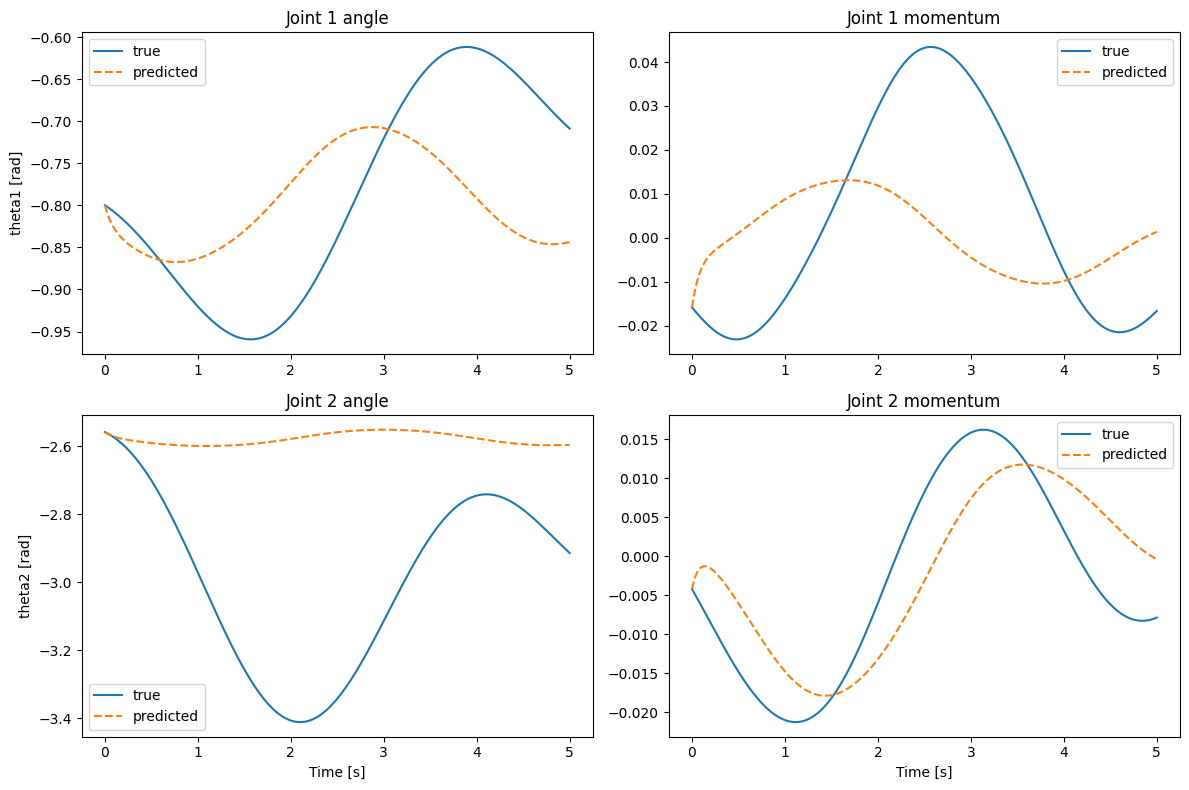

In [217]:
def predict_next(x_numpy, dt, u_numpy):
    """
    x_numpy: (4,) or (batch,4) array [q1,q2,p1,p2]
    dt: float
    u_numpy: optional (batch, u_dim) control input for the step (if None, zero)
    """
    x_np = np.asarray(x_numpy, dtype=np.float32)
    squeeze = False
    if x_np.ndim == 1:
        x_np = x_np.reshape(1, -1)
        squeeze = True

    xt = torch.tensor(x_np, dtype=torch.float32)  # device cpu by default

    # control
    u_np = np.asarray(u_numpy, dtype=np.float32)
    if u_np.ndim == 1:
        u_np = u_np.reshape(1, -1)
    zero_u = torch.tensor(u_np, dtype=torch.float32)

    # IMPORTANT: do NOT use torch.no_grad() here because dynamics uses autograd.grad inside.
    # But we are not going to call backward(), so this is safe.
    # Optionally, protect from accidental grad accumulation elsewhere:
    with torch.set_grad_enabled(True):
        def ode_fn(t, x, u_in=zero_u):
            return dynamics(t, x, u_in)

        # --- one RK4 integration step
        x_next = rk4_step(ode_fn, xt, 0.0, dt)

    out = x_next.detach().cpu().numpy()
    if squeeze:
        return out[0]
    return out

# Store predicted trajectories
pred_traj = {
    "theta1": [],
    "theta2": [],
    "p1": [],
    "p2": []
}

tn = 1

# Loop over time steps
traj = trajectories['states'][tn]  # assuming single trajectory
x_prev = np.array([traj["theta1"][0],
                   traj["theta2"][0],
                   traj["p1"][0],
                   traj["p2"][0]], dtype=np.float32)

# Store predicted
pred_traj["theta1"].append(x_prev[0])
pred_traj["theta2"].append(x_prev[1])
pred_traj["p1"].append(x_prev[2])
pred_traj["p2"].append(x_prev[3])

for i in range(len(traj["theta1"])-1):
    # Construct state vector x and control u
    x_numpy = x_prev
    u_numpy = np.array([traj["tau1"][i], traj["tau2"][i]], dtype=np.float32)

    # Predict next state
    x_next = predict_next(x_numpy, dt, u_numpy)

    # Store predicted
    pred_traj["theta1"].append(x_next[0])
    pred_traj["theta2"].append(x_next[1])
    pred_traj["p1"].append(x_next[2])
    pred_traj["p2"].append(x_next[3])

    # Update x_prev
    x_prev = x_next

# Convert to numpy arrays
for k in pred_traj:
    pred_traj[k] = np.array(pred_traj[k])

# Plot results
time = np.arange(len(traj["theta1"])) * dt

fig, axs = plt.subplots(2,2, figsize=(12,8))
axs[0,0].plot(time, traj["theta1"], label="true")
axs[0,0].plot(time, pred_traj["theta1"], '--', label="predicted")
axs[0,0].set_title("Joint 1 angle")
axs[0,0].set_ylabel("theta1 [rad]")
axs[0,0].legend()

axs[0,1].plot(time, traj["p1"], label="true")
axs[0,1].plot(time, pred_traj["p1"], '--', label="predicted")
axs[0,1].set_title("Joint 1 momentum")
axs[0,1].legend()

axs[1,0].plot(time, traj["theta2"], label="true")
axs[1,0].plot(time, pred_traj["theta2"], '--', label="predicted")
axs[1,0].set_title("Joint 2 angle")
axs[1,0].set_ylabel("theta2 [rad]")
axs[1,0].set_xlabel("Time [s]")
axs[1,0].legend()

axs[1,1].plot(time, traj["p2"], label="true")
axs[1,1].plot(time, pred_traj["p2"], '--', label="predicted")
axs[1,1].set_title("Joint 2 momentum")
axs[1,1].set_xlabel("Time [s]")
axs[1,1].legend()

plt.tight_layout()
plt.show()



Saved modular model state to modular_hnn_state.pth


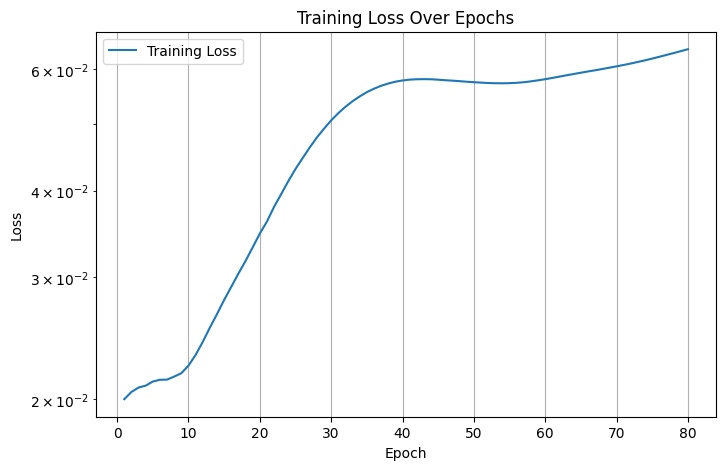

In [218]:
# Save subnetwork/state (no duplicate keys)
torch.save({
    'mass_nn': mass_nn.state_dict(),
    'diss_nn': diss_nn.state_dict(),
    'actuator_nn': actuator_nn.state_dict(),
}, "modular_hnn_state.pth")
print("Saved modular model state to modular_hnn_state.pth")

# Plot training loss (use accumulated history)
plt.figure(figsize=(8,5))
plt.plot(range(1, len(loss_history)+1), loss_history, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()

In [211]:
# import math
# import matplotlib.pyplot as plt
# import torch
# import torch.optim as optim
# import torch.nn as nn
# from torch.utils.data import Dataset, DataLoader

# # hyperparams
# batch_size = 256
# lr = 1e-3
# epochs = 250
# device = torch.device("cpu") #if torch.backends.mps.is_available() else torch.device("cpu")
# # device = torch.device("cuda")  # or "cuda"
# q_dim = 2

# # instantiate networks 
# mass_nn = LowerTriangularNN(q_dim, hidden_dims=(128,128,128)).to(device)
# diss_nn = LowerTriangularNN(q_dim, hidden_dims=(64,64)).to(device)
# actuator_nn = ActuatorNN(q_dim, u_dim=2, hidden=(64,64)).to(device)

# ham_model = HamiltonianNN(q_dim, mass_nn)
# dynamics = HamiltonianDynamics(ham_model, diss_nn=diss_nn, actuator_nn=actuator_nn).to(device)

# optim_ = optim.Adam(dynamics.parameters(), lr=lr,weight_decay=1e-6, betas = [0.9, 0.999])
# mse = nn.MSELoss()

# # convert to torch
# X_t = torch.from_numpy(X).float().to(device)   # [N, 4]
# Y_t = torch.from_numpy(Y).float().to(device)   # [N, 4]
# U_t = torch.from_numpy(U).float().to(device)   # [N, 2]

# N, D = X_t.shape
# num_batches = math.ceil(N / batch_size)

# # compute dt (scalar)
# dt = float((t_eval[1] - t_eval[0]))

# # RK4 requires a scalar time 
# t0 = float(t_eval[0])

# loss_history=[]

# for epoch in range(epochs):
#     perm = torch.randperm(N)
#     epoch_loss = 0.0

#     for b in range(num_batches):
#         idx = perm[b*batch_size:(b+1)*batch_size]

#         x0 = X_t[idx].clone()       # [B, 4], initial state for this batch
#         y_true = Y_t[idx]           # [B, 4], target next-step
#         u_batch = U_t[idx]          # [B, 2], control input for this batch

#         optim_.zero_grad()

#         # --- wrap dynamics into ODE function with batch control
#         def ode_fn(t, x, u_in=u_batch):
#             return dynamics(t, x, u_in)

#         # --- one RK4 integration step
#         x_pred = rk4_step(ode_fn, x0, t0, dt)

#         # --- compute loss and backprop
#         loss = mse(x_pred, y_true)
#         loss.backward()
#         optim_.step()

#         # --- update epoch loss
#         epoch_loss += loss.item()

#     epoch_loss /= num_batches
#     loss_history.append(epoch_loss)
#     print(f"Epoch {epoch+1}/{epochs}  Loss: {epoch_loss:.6e}")


# # Save subnetwork/state (no duplicate keys)
# torch.save({
#     'mass_nn': mass_nn.state_dict(),
#     'diss_nn': diss_nn.state_dict(),
#     'actuator_nn': actuator_nn.state_dict(),
# }, "modular_hnn_state.pth")
# print("Saved modular model state to modular_hnn_state.pth")

# # Plot training loss (use accumulated history)
# plt.figure(figsize=(8,5))
# plt.plot(range(1, len(loss_history)+1), loss_history, label="Training Loss")
# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.yscale("log")
# plt.title("Training Loss Over Epochs")
# plt.legend()
# plt.grid(True)
# plt.show()
